In [62]:
from src import base
import numpy as np 
import matplotlib.pyplot as plt 

Training a simple model

In [57]:
import torch 
import torch.nn as nn

In [58]:
model = base.VNet()
opt = torch.optim.AdamW(model.parameters(), lr=0.1)

In [59]:
loss_curve = []
for _ in range(5000):
    x = torch.rand(2048, 2)     # collocation points in [0,1]^2
    loss = (base.residual(model, x)**2).mean()
    loss_curve.append(loss.item())
    opt.zero_grad()
    loss.backward() 
    opt.step()

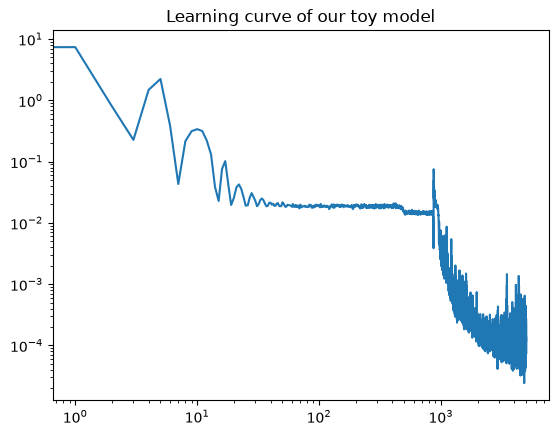

In [60]:
plt.figure()
plt.loglog(list(range(len(loss_curve))),loss_curve)
plt.title("Learning curve of our toy model")
plt.show()

Test of the trained model on a simple (randomly generated) example

# Visualisation of the error on a simple wind field

In [65]:
from src import base

In [66]:
x = torch.rand(2048,2)
wind_field = base.wind_jet_along_x(x,rotation_angle=15)

AttributeError: module 'src.base' has no attribute 'wind_jet_along_x'

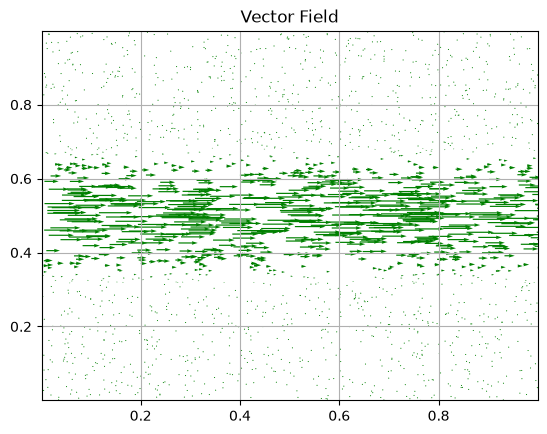

In [23]:
x_ = np.array([x[i,0] for i in range(x.shape[0])])
y_ = np.array([x[i,1] for i in range(x.shape[0])])

# Directional vectors
u = np.array([wind_field[i,0].item() for i in range(wind_field.shape[0])])
v = np.array([wind_field[i,1].item() for i in range(wind_field.shape[0])])

plt.figure()

# Plotting Vector Field with QUIVER
plt.quiver(x_, y_, u, v, color='g')
plt.title('Vector Field')

plt.xlim(x_.min(), x_.max())
plt.ylim(y_.min(), y_.max())

# Show plot with grid
plt.grid()
plt.show()

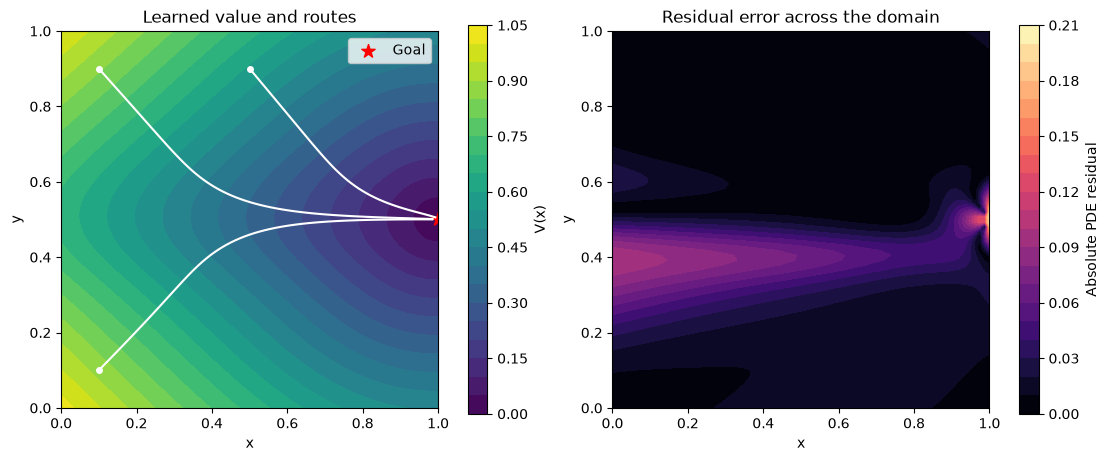

In [24]:
# Regular grid over the training domain
n = 80
axis = torch.linspace(0, 1, n)
xx, yy = torch.meshgrid(axis, axis, indexing="xy")
points = torch.stack((xx.reshape(-1), yy.reshape(-1)), dim=1)

# Evaluate V and its PDE residual
values = model(points).detach().reshape(n, n).numpy()
errors = base.residual(model, points).abs().detach().reshape(n, n).numpy()
X, Y = xx.numpy(), yy.numpy()

fig, (ax_v, ax_err) = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

v_plot = ax_v.contourf(X, Y, values, levels=20, cmap="viridis")
fig.colorbar(v_plot, ax=ax_v, label="V(x)")
ax_v.scatter(*base.goal.squeeze().numpy(), marker="*", color="red", s=100, label="Goal")

for start in ([0.1, 0.1], [0.1, 0.9], [0.5, 0.9]):
    path = base.route(model, start)
    ax_v.plot(path[:, 0], path[:, 1], color="white", linewidth=1.5)
    ax_v.plot(*start, "wo", markersize=4)

ax_v.set(title="Learned value and routes", xlabel="x", ylabel="y",
         xlim=(0, 1), ylim=(0, 1), aspect="equal")
ax_v.legend()

err_plot = ax_err.contourf(X, Y, errors, levels=20, cmap="magma")
fig.colorbar(err_plot, ax=ax_err, label="Absolute PDE residual")
ax_err.set(title="Residual error across the domain", xlabel="x", ylabel="y",
           xlim=(0, 1), ylim=(0, 1), aspect="equal")

plt.show()